In [ ]:
!pip install -q transformers accelerate datasets torch tensorflow scikit-learn pandas numpy matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)

from torch.utils.data import Dataset

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [ ]:
!pip install -q kagglehub

import kagglehub
import glob

path = kagglehub.dataset_download("snap/amazon-fine-food-reviews")

files = glob.glob(path + "/**/Reviews.csv", recursive=True)

df = pd.read_csv(files[0], usecols=["Score", "Text"])

print(df.head())

print(df.shape)

print(df.info())

100%|██████████| 242M/242M [00:01<00:00, 179MB/s]

Extracting files...


   Score                                               Text
0      5  I have bought several of the Vitality canned d...
1      1  Product arrived labeled as Jumbo Salted Peanut...
2      4  This is a confection that has been around a fe...
3      2  If you are looking for the secret ingredient i...
4      5  Great taffy at a great price.  There was a wid...
(568454, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   Score   568454 non-null  int64 
 1   Text    568454 non-null  object
dtypes: int64(1), object(1)
memory usage: 8.7+ MB
None


In [ ]:
df = df[["Text", "Score"]].dropna()

df["Text"] = df["Text"].astype(str).str.strip()

df["sentiment"] = df["Score"].apply(
    lambda x: "negative" if x <= 2
    else "neutral" if x == 3
    else "positive"
)

df = df[df["Text"] != ""]

print(df["sentiment"].value_counts())

sentiment
positive    443777
negative     82037
neutral      42640
Name: count, dtype: int64


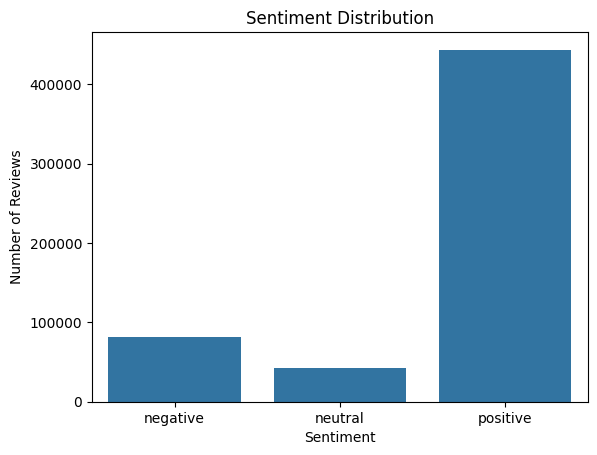

In [ ]:
sns.countplot(
    data=df,
    x="sentiment",
    order=["negative", "neutral", "positive"]
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [ ]:
le = LabelEncoder()

df["sentiment_label"] = le.fit_transform(
    df["sentiment"]
)

print("Label mapping:")

for i, label in enumerate(le.classes_):
    print(label, "=", i)

Label mapping:
negative = 0
neutral = 1
positive = 2


In [ ]:
le = LabelEncoder()
df["sentiment_label"] = le.fit_transform(df["sentiment"])

X = df["Text"]
y = df["sentiment_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

NameError: name 'LabelEncoder' is not defined

In [ ]:
model_name = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3
)

bert_model.to(device)

NameError: name 'AutoTokenizer' is not defined

In [ ]:
train_encodings = tokenizer(
    X_train.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

test_encodings = tokenizer(
    X_test.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

NameError: name 'tokenizer' is not defined

In [ ]:
class ReviewDataset(Dataset):

    def __init__(self, encodings, labels):

        self.encodings = encodings
        self.labels = list(labels)

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return item

    def __len__(self):

        return len(self.labels)

In [ ]:
train_dataset = ReviewDataset(
    train_encodings,
    y_train
)

test_dataset = ReviewDataset(
    test_encodings,
    y_test
)

In [ ]:
def compute_metrics(pred):

    labels = pred.label_ids

    predictions = np.argmax(
        pred.predictions,
        axis=1
    )

    return {
        "accuracy": accuracy_score(
            labels,
            predictions
        ),

        "precision": precision_score(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "recall": recall_score(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "f1": f1_score(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        )
    }

In [ ]:
training_args = TrainingArguments(
    output_dir="./bert_results",
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=50,
    report_to="none"
)

In [ ]:
trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics,
    processing_class=tokenizer
)

trainer.train()

In [ ]:
bert_results = trainer.predict(test_dataset)

y_pred_bert = np.argmax(
    bert_results.predictions,
    axis=1
)

print("BERT Accuracy:",
      accuracy_score(y_test, y_pred_bert))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_bert,
    target_names=le.classes_,
    zero_division=0
))

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred_bert
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.title("BERT Confusion Matrix")

plt.show()

In [ ]:
new_review = [
    "This product is excellent and I absolutely love it!"
]

inputs = tokenizer(
    new_review,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=128
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

bert_model.eval()

with torch.no_grad():

    outputs = bert_model(**inputs)

prediction = torch.argmax(
    outputs.logits,
    dim=1
)

print(
    "Predicted Sentiment:",
    le.inverse_transform(
        prediction.cpu().numpy()
    )[0]
)

In [ ]:
lstm_tokenizer = Tokenizer(num_words=10000)

lstm_tokenizer.fit_on_texts(X_train)

X_train_seq = lstm_tokenizer.texts_to_sequences(
    X_train
)

X_test_seq = lstm_tokenizer.texts_to_sequences(
    X_test
)

In [ ]:
max_length = 100

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print(X_train_pad.shape)
print(X_test_pad.shape)

In [ ]:
lstm_model = Sequential([

    Embedding(
        input_dim=10000,
        output_dim=128,
        input_length=max_length
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(32, activation="relu"),

    Dense(3, activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_pad,
    np.array(y_train),
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.title("LSTM Training Accuracy")

plt.legend()
plt.show()

In [ ]:
lstm_loss, lstm_accuracy = lstm_model.evaluate(
    X_test_pad,
    np.array(y_test)
)

print("LSTM Accuracy:", lstm_accuracy)

In [ ]:
lstm_probabilities = lstm_model.predict(
    X_test_pad
)

y_pred_lstm = np.argmax(
    lstm_probabilities,
    axis=1
)

print(classification_report(
    y_test,
    y_pred_lstm,
    target_names=le.classes_,
    zero_division=0
))

In [ ]:
cm_lstm = confusion_matrix(
    y_test,
    y_pred_lstm
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.title("LSTM Confusion Matrix")

plt.show()

In [ ]:
new_review = [
    "The product quality is very bad"
]

new_sequence = lstm_tokenizer.texts_to_sequences(
    new_review
)

new_pad = pad_sequences(
    new_sequence,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

prediction = lstm_model.predict(new_pad)

predicted_class = np.argmax(
    prediction,
    axis=1
)

print(
    "Predicted Sentiment:",
    le.inverse_transform(predicted_class)[0]
)

In [ ]:
bert_accuracy = accuracy_score(
    y_test, y_pred_bert
)

lstm_accuracy = accuracy_score(
    y_test, y_pred_lstm
)

bert_precision = precision_score(
    y_test, y_pred_bert,
    average="weighted",
    zero_division=0
)

lstm_precision = precision_score(
    y_test, y_pred_lstm,
    average="weighted",
    zero_division=0
)

bert_recall = recall_score(
    y_test, y_pred_bert,
    average="weighted",
    zero_division=0
)

lstm_recall = recall_score(
    y_test, y_pred_lstm,
    average="weighted",
    zero_division=0
)

bert_f1 = f1_score(
    y_test, y_pred_bert,
    average="weighted",
    zero_division=0
)

lstm_f1 = f1_score(
    y_test, y_pred_lstm,
    average="weighted",
    zero_division=0
)

In [ ]:
comparison = pd.DataFrame({

    "Model": ["BERT", "LSTM"],

    "Accuracy": [
        bert_accuracy,
        lstm_accuracy
    ],

    "Precision": [
        bert_precision,
        lstm_precision
    ],

    "Recall": [
        bert_recall,
        lstm_recall
    ],

    "F1 Score": [
        bert_f1,
        lstm_f1
    ]
})

print(comparison)

In [ ]:
comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("BERT vs LSTM Performance Comparison")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(loc="lower right")

plt.show()

In [ ]:
bert_model.save_pretrained(
    "/content/bert_sentiment_model"
)

tokenizer.save_pretrained(
    "/content/bert_sentiment_model"
)

In [ ]:
lstm_model.save(
    "/content/lstm_sentiment_model.keras"
)

import pickle

with open("/content/lstm_tokenizer.pkl", "wb") as file:
    pickle.dump(lstm_tokenizer, file)

with open("/content/label_encoder.pkl", "wb") as file:
    pickle.dump(le, file)

print("All models saved successfully!")